In [1]:
!pip install numpy matplotlib yfinance

import numpy as np
import yfinance
from matplotlib import pyplot as plt

In [20]:
data = yfinance.download("AMZN", start="2025-01-01", end="2026-01-01")
close = data["Close"]

[*********************100%***********************]  1 of 1 completed


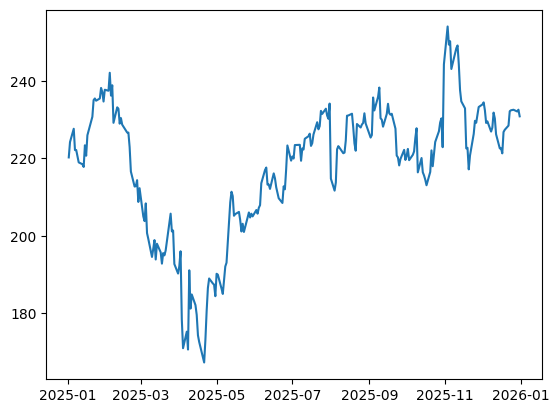

In [21]:
plt.plot(close)

[0.0001888] [0.0216269]


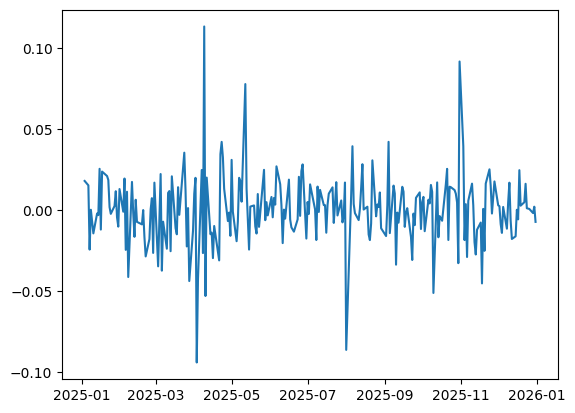

In [40]:
log_returns = np.log(close/close.shift(1)).iloc[1:]
mu = log_returns.mean().values
sigma = log_returns.std().values

print(mu, sigma)

plt.plot(log_returns)

In [57]:
def MC_simulation(T, N, mu, sigma, close):
    dt = 1
    Z = np.random.standard_normal(size=(T, N))
    returns = np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
    
    S0 = close.iloc[-1].values[0]
    paths = S0*np.cumprod(returns, axis=0)

    return paths

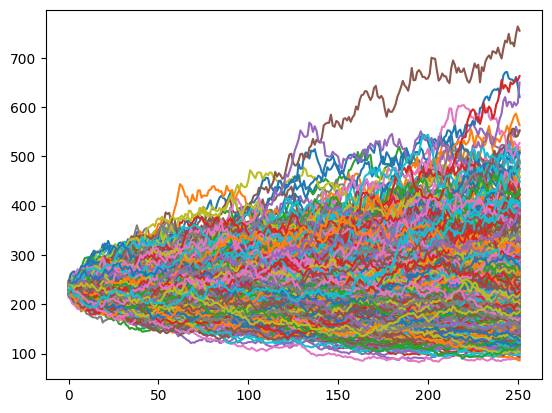

In [65]:
T = 252
N = 1000
r = 0.05/T

paths = MC_simulation(T, N, r, sigma, close) 
                      
plt.plot(paths)
plt.show()

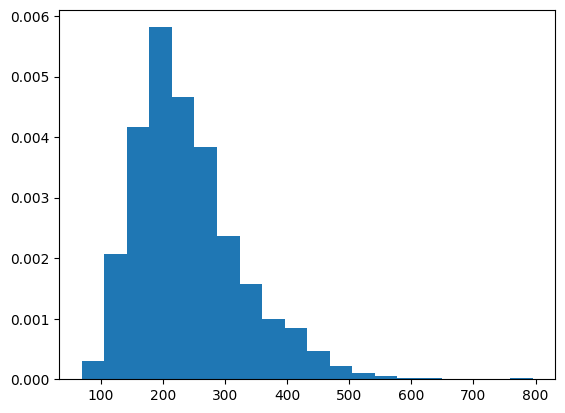

In [59]:
"""
X = paths[-1, :]


sigma = X.std()

x = np.linspace(X.min(), X.max(), 500)

pdf = 1 / np.sqrt(2*np.pi*sigma**2) * np.exp(
    -0.5 * (x-mu)**2 / sigma**2
)
"""
plt.hist(paths[-1, :], density=True, bins=20)
#plt.plot(x, pdf, c="orange", lw=2)
plt.show()

In [2]:
!ls -la

total 1528
drwxr-xr-x   7 kokku  staff     224  5 nov 19:36 .
drwxr-xr-x   4 kokku  staff     128  4 nov 22:30 ..
drwxr-xr-x  12 kokku  staff     384  5 nov 19:36 .git
-rw-r--r--   1 kokku  staff       0  5 nov 19:36 .gitignore
drwxr-xr-x   3 kokku  staff      96  5 nov 19:35 .ipynb_checkpoints
-rw-r--r--@  1 kokku  staff  777062  5 nov 19:31 option_pricing.ipynb
-rw-r--r--   1 kokku  staff     109  4 nov 22:30 README.md


## European Option Pricing with Black-Scholes

In [90]:
T = 252
N = 1000 #250
#r = 0.05
K = 230 

S0 = close.iloc[-1].values[0]
Z = np.random.standard_normal(N)
ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)

payoff = np.maximum(ST - K, 0)
price = np.exp(-r*T) * np.mean(payoff)

37.7325366763412


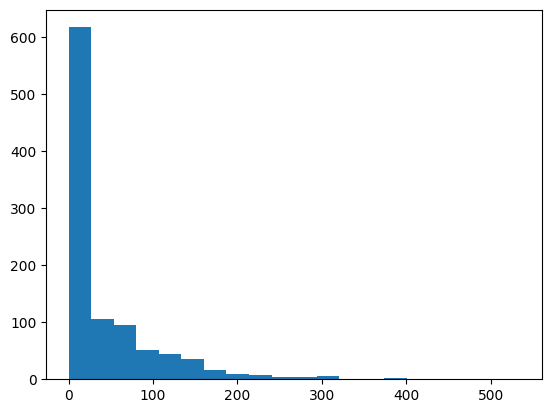

In [91]:
print(price)
plt.hist(payoff, bins=20)
plt.show()

## American Options: Longstaff–Schwartz Algorithm

In [62]:
def exercise(X, K):
    return np.maximum(K - X, 0)

In [92]:
X = paths[-1,:]
Y = exercise(X, K)
xplot = np.linspace(np.min(X), np.max(X), N)

p = np.polynomial.Chebyshev.fit(X, Y, 4)

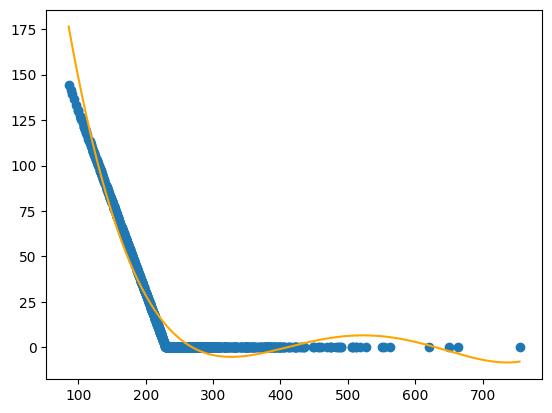

In [93]:
plt.scatter(X, Y)
plt.plot(xplot, p(xplot), c="orange")

In [83]:
dt = 1
#K = 270
deg = 4

Chat_list = [] # Remember to reverse it
tau = np.full(N, T-1, dtype=int)
for t in range(T-2, 0, -1):
    
    X = paths[t,:]
    V = np.exp(-r*(tau-t)*dt)*exercise(paths[tau, np.arange(N)], K)

    itm = X < K
    if itm.sum() > deg+1: # Check that it has enough ITM trajectories to have a good fit
        C_hat = np.polynomial.Chebyshev.fit(X[itm], V[itm], deg) # We want to fit only the ITM part
        tau[itm & (C_hat(X) < K - X)] = t
        Chat_list.append(C_hat)
    else:
        Chat_list.append(None)

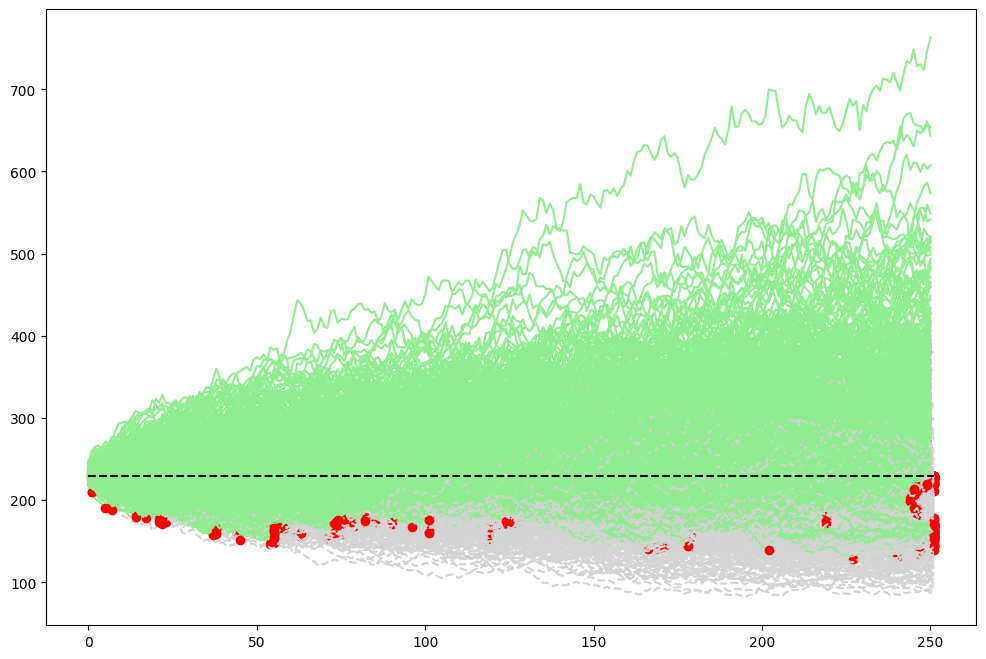

In [84]:
plt.figure(figsize=(12, 8))

for idx in range(paths.shape[1]):
    exercise_time = tau[idx]
    path = paths[:,idx]
    plt.plot(range(exercise_time, T), path[exercise_time:], c="lightgrey", linestyle="--")
    plt.plot(range(exercise_time), path[:exercise_time], c="lightgreen")
    
    if path[exercise_time] < K:
        plt.scatter(exercise_time, path[exercise_time], c="red", zorder=2)

plt.plot(np.arange(T), K*np.ones(T), linestyle="--", c="black")

In [87]:
european = np.exp(-r*T)*np.mean(np.maximum(K - paths[-1,:], 0))
american = 1/N * np.sum(np.exp(-r*(tau+1)*dt)*np.maximum(K - paths[tau, np.arange(N)], 0))

print(european)
print(american)

25.01111454479811
26.480399615407777


In [89]:
#np.exp(-r*T)*np.mean(np.maximum(paths[-1,:] - K, 0))

np.float64(37.53162474791024)

In [86]:
print(american - european)

1.469285070609665
